In [1]:
# Step I : Import the libraries
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
from tensorflow.keras.utils import image_dataset_from_directory

In [3]:
# Step II : Load the Dataset 
train_dir = "cats_and_dogs_filtered/train"
test_dir = "cats_and_dogs_filtered/validation"

In [5]:
# Step III : Load the images
train_data = image_dataset_from_directory(
    train_dir,
    image_size=(224,224),
    batch_size=64,
    label_mode='binary'
)

test_data = image_dataset_from_directory(
    test_dir,
    image_size=(224,224),
    batch_size=64,
    label_mode='binary'
)

Found 202 files belonging to 2 classes.
Found 202 files belonging to 2 classes.


In [6]:
# Step IV : Preprocessing 
train_data = train_data.map(lambda x,y:(preprocess_input(x),y))
test_data = test_data.map(lambda x,y:(preprocess_input(x),y))

In [8]:
# Step V: Load Pretrained Model
base_model = VGG16(
    weights='imagenet',
    include_top=False,
    input_shape=(224,224,3)
)
base_model.trainable=False

In [10]:
# Step VI : build the model 
model = tf.keras.Sequential([
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(128,activation='relu'),
    tf.keras.layers.Dense(1,activation='sigmoid')
])

In [11]:
# Step 7 : Feature Extraction model 
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    train_data,
    epochs=3,
    validation_data=test_data
)

# evaluate the model 
loss,accuracy = model.evaluate(test_data)
print(accuracy)

Epoch 1/3
4/4 ━━━━━━━━━━━━━━━━━━━━ 5s 504ms/step - accuracy: 0.4950 - loss: 1.6133 - val_accuracy: 0.5099 - val_loss: 1.0434
Epoch 2/3
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 182ms/step - accuracy: 0.5594 - loss: 0.8527 - val_accuracy: 0.5693 - val_loss: 0.9485
Epoch 3/3
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 227ms/step - accuracy: 0.5693 - loss: 0.9185 - val_accuracy: 0.5347 - val_loss: 1.0592
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 55ms/step - accuracy: 0.5347 - loss: 1.0592
0.5346534848213196


In [12]:
# Step 8 : Fine Tuning model 
base_model.trainable=True

for layers in base_model.layers[:-4]:
    layers.trainable=False

# compile the model
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# train the model 
history2 = model.fit(
    train_data,
    epochs=3,
    validation_data=test_data
)

# evaluate the model 
loss,accuracy = model.evaluate(test_data)
print(accuracy)

Epoch 1/3
4/4 ━━━━━━━━━━━━━━━━━━━━ 3s 292ms/step - accuracy: 0.5594 - loss: 0.9619 - val_accuracy: 0.5396 - val_loss: 1.0091
Epoch 2/3
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 217ms/step - accuracy: 0.5743 - loss: 0.9111 - val_accuracy: 0.5446 - val_loss: 0.9662
Epoch 3/3
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 217ms/step - accuracy: 0.5792 - loss: 0.8652 - val_accuracy: 0.5693 - val_loss: 0.9289
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.5693 - loss: 0.9289
0.5693069100379944


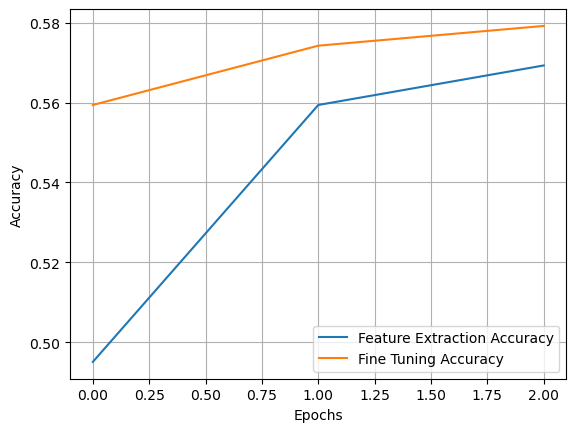

In [15]:
# Step 9 : Plotting 
plt.plot(history.history['accuracy'],label='Feature Extraction Accuracy')
plt.plot(history2.history['accuracy'],label='Fine Tuning Accuracy')
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()